In [6]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [8]:
kepler=pd.read_csv("C:/David Mills/projects/NASAexoplanet/data/raw/kepler/cumulative_2026.11.13_03.57.53.csv",comment="#")
tess=pd.read_csv("C:/David Mills/projects/NASAexoplanet/data/raw/tess/TOI_2026.11.13_04.01.31.csv",comment="#")

In [9]:
print("KEPLER")
kepler.info()

print("\nTESS")
tess.info()

KEPLER
<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Columns: 141 entries, rowid to koi_dikco_msky_err
dtypes: float64(117), int64(7), object(1), str(16)
memory usage: 10.3+ MB

TESS
<class 'pandas.DataFrame'>
RangeIndex: 8175 entries, 0 to 8174
Data columns (total 87 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              8175 non-null   int64  
 1   toi                8175 non-null   float64
 2   toipfx             8175 non-null   int64  
 3   tid                8175 non-null   int64  
 4   ctoi_alias         8175 non-null   float64
 5   pl_pnum            8175 non-null   int64  
 6   tfopwg_disp        8173 non-null   str    
 7   rastr              8175 non-null   str    
 8   ra                 8175 non-null   float64
 9   raerr1             0 non-null      float64
 10  raerr2             0 non-null      float64
 11  decstr             8175 non-null   str    
 12  dec                8175 non

In [10]:
display(kepler.describe().T)
display(tess.describe().T)

,count,mean,std,min,25%,50%,75%,max
rowid,9564.0,4.782500e+03,2.761033e+03,1.000,2391.750,4782.500,7173.250,9564.0
kepid,9564.0,7.690628e+06,2.653459e+06,757450.000,5556034.250,7906892.000,9873066.500,12935144.0
koi_score,8054.0,4.808294e-01,4.769285e-01,0.000,0.000,0.334,0.998,1.0
koi_fpflag_nt,9564.0,2.085947e-01,4.767290e+00,0.000,0.000,0.000,0.000,465.0
koi_fpflag_ss,9564.0,2.327478e-01,4.226049e-01,0.000,0.000,0.000,0.000,1.0
...,...,...,...,...,...,...,...,...
koi_dikco_mra_err,8994.0,4.253372e-01,6.021498e-01,0.067,0.087,0.250,0.590,33.0
koi_dikco_mdec,8994.0,-7.674883e-02,2.553758e+00,-76.600,-0.390,-0.017,0.300,34.0
koi_dikco_mdec_err,8994.0,4.366836e-01,5.675354e-01,0.067,0.090,0.270,0.600,22.0
koi_dikco_msky,8994.0,1.812566e+00,2.986376e+00,0.000,0.210,0.583,1.970,89.6


,count,mean,std,min,25%,50%,75%,max
rowid,8175.0,4.088000e+03,2.360064e+03,1.000000,2.044500e+03,4.088000e+03,6.131500e+03,8.175000e+03
toi,8175.0,3.961617e+03,2.276568e+03,101.010000,1.968510e+03,3.954010e+03,5.934510e+03,7.936010e+03
toipfx,8175.0,3.961606e+03,2.276568e+03,101.000000,1.968500e+03,3.954000e+03,5.934500e+03,7.936000e+03
tid,8175.0,2.441813e+08,1.608285e+08,2876.000000,1.297340e+08,2.459477e+08,3.526822e+08,2.041563e+09
ctoi_alias,8175.0,2.441813e+08,1.608285e+08,2876.010000,1.297340e+08,2.459477e+08,3.526822e+08,2.041563e+09
...,...,...,...,...,...,...,...,...
st_rad,7544.0,1.400522e+00,1.566177e+00,0.114827,8.900000e-01,1.236045e+00,1.660000e+00,1.020300e+02
st_raderr1,6007.0,7.440524e-02,8.219482e-02,0.003357,5.000000e-02,6.000000e-02,8.000000e-02,1.723020e+00
st_raderr2,6007.0,-7.440524e-02,8.219482e-02,-1.723020,-8.000000e-02,-6.000000e-02,-5.000000e-02,-3.357300e-03
st_radlim,8175.0,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [11]:
print("KEPLER DISPOSITION DISTRIBUTION")
print(kepler["koi_disposition"].value_counts(dropna=False))

print("\nTESS DISPOSITION DISTRIBUTION")
print(tess["tfopwg_disp"].value_counts(dropna=False))

KEPLER DISPOSITION DISTRIBUTION
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

TESS DISPOSITION DISTRIBUTION
tfopwg_disp
PC     4832
FP     1319
CP      821
KP      609
APC     494
FA       98
NaN       2
Name: count, dtype: int64


In [12]:
print("KEPLER DISPOSITION (%)")
print(
    kepler["koi_disposition"]
    .value_counts(normalize=True, dropna=False) * 100
)

print("\nTESS DISPOSITION (%)")
print(
    tess["tfopwg_disp"]
    .value_counts(normalize=True, dropna=False) * 100
)

KEPLER DISPOSITION (%)
koi_disposition
FALSE POSITIVE    50.595985
CONFIRMED         28.732748
CANDIDATE         20.671267
Name: proportion, dtype: float64

TESS DISPOSITION (%)
tfopwg_disp
PC     59.107034
FP     16.134557
CP     10.042813
KP      7.449541
APC     6.042813
FA      1.198777
NaN     0.024465
Name: proportion, dtype: float64


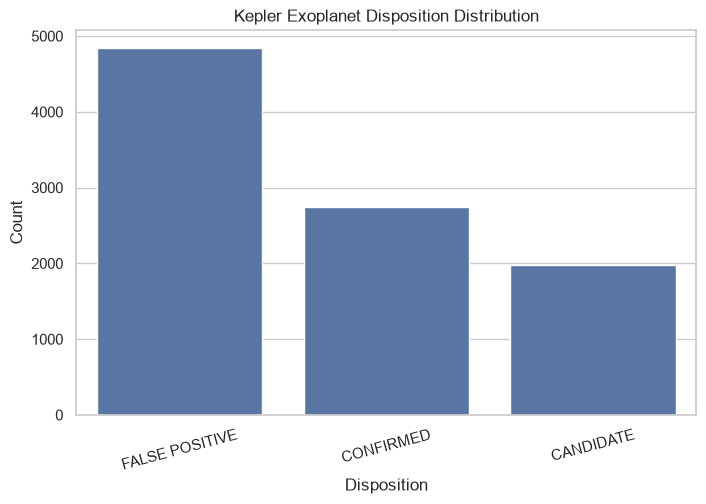

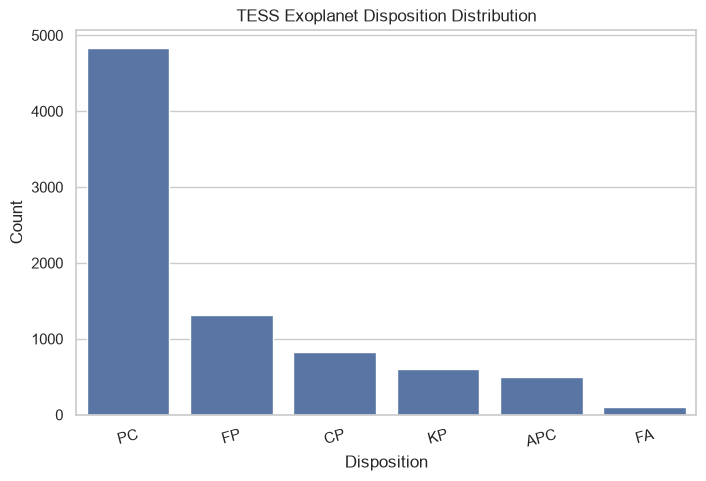

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Kepler target distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=kepler,
    x='koi_disposition',
    order=kepler['koi_disposition'].value_counts().index
)

plt.title('Kepler Exoplanet Disposition Distribution')
plt.xlabel('Disposition')
plt.ylabel('Count')
plt.xticks(rotation=15)
plt.show()


# TESS target distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=tess,
    x='tfopwg_disp',
    order=tess['tfopwg_disp'].value_counts().index
)

plt.title('TESS Exoplanet Disposition Distribution')
plt.xlabel('Disposition')
plt.ylabel('Count')
plt.xticks(rotation=15)
plt.show()

In [14]:
# Kepler missing values

kepler_missing = pd.DataFrame({
    'Missing Values': kepler.isnull().sum(),
    'Missing Percentage': (kepler.isnull().mean() * 100)
})

kepler_missing = kepler_missing.sort_values(
    by='Missing Percentage',
    ascending=False
)

print("KEPLER MISSING VALUES")
print(kepler_missing.head(30))




KEPLER MISSING VALUES
                  Missing Values  Missing Percentage
koi_incl_err1               9564          100.000000
koi_sma_err2                9564          100.000000
koi_sma_err1                9564          100.000000
koi_teq_err1                9564          100.000000
koi_teq_err2                9564          100.000000
koi_longp_err2              9564          100.000000
koi_ingress                 9564          100.000000
koi_ingress_err2            9564          100.000000
koi_ingress_err1            9564          100.000000
koi_longp_err1              9564          100.000000
koi_longp                   9564          100.000000
koi_eccen_err2              9564          100.000000
koi_eccen_err1              9564          100.000000
koi_sage_err1               9564          100.000000
koi_sage_err2               9564          100.000000
koi_sage                    9564          100.000000
koi_model_dof               9564          100.000000
koi_model_chisq         

In [15]:
# TESS missing values

tess_missing = pd.DataFrame({
    'Missing Values': tess.isnull().sum(),
    'Missing Percentage': (tess.isnull().mean() * 100)
})

tess_missing = tess_missing.sort_values(
    by='Missing Percentage',
    ascending=False
)

print("TESS MISSING VALUES")
print(tess_missing.head(30))

TESS MISSING VALUES
                Missing Values  Missing Percentage
decerr1                   8175          100.000000
raerr1                    8175          100.000000
raerr2                    8175          100.000000
decerr2                   8175          100.000000
pl_insolerr2              8175          100.000000
pl_insollim               8175          100.000000
pl_insolsymerr            8175          100.000000
pl_eqterr1                8175          100.000000
pl_eqterr2                8175          100.000000
pl_eqtlim                 8175          100.000000
pl_eqtsymerr              8175          100.000000
pl_insolerr1              8175          100.000000
st_loggerr2               2399           29.345566
st_loggerr1               2399           29.345566
st_raderr1                2168           26.519878
st_raderr2                2168           26.519878
pl_radeerr2               1612           19.718654
pl_radeerr1               1612           19.718654
st_logg    

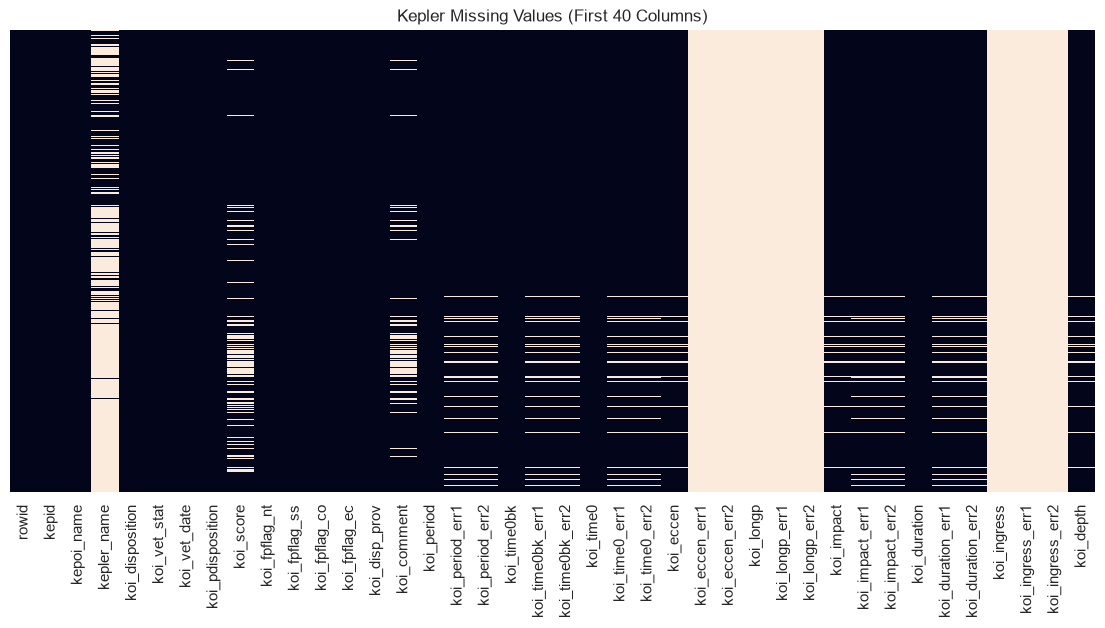

In [16]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    kepler.isnull().iloc[:, :40],
    cbar=False,
    yticklabels=False
)

plt.title("Kepler Missing Values (First 40 Columns)")
plt.show()

In [17]:
# Kepler
kepler_empty = kepler.columns[kepler.isnull().all()]

# TESS
tess_empty = tess.columns[tess.isnull().all()]

print("Kepler completely empty columns:", len(kepler_empty))
print(list(kepler_empty))

print("\nTESS completely empty columns:", len(tess_empty))
print(list(tess_empty))

Kepler completely empty columns: 19
['koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_sma_err1', 'koi_sma_err2', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_model_dof', 'koi_model_chisq', 'koi_sage', 'koi_sage_err1', 'koi_sage_err2']

TESS completely empty columns: 12
['raerr1', 'raerr2', 'decerr1', 'decerr2', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_insolsymerr', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'pl_eqtsymerr']


In [18]:
def missing_summary(df, name):

    missing = df.isnull().mean() * 100

    print(f"\n{name} DATASET")
    print("----------------------")

    print("Total columns:", df.shape[1])

    print("No missing values:", (missing == 0).sum())

    print("1-25% missing:", ((missing > 0) & (missing <= 25)).sum())

    print("25-50% missing:", ((missing > 25) & (missing <= 50)).sum())

    print("50-75% missing:", ((missing > 50) & (missing <= 75)).sum())

    print("75-99% missing:", ((missing > 75) & (missing < 100)).sum())

    print("100% missing:", (missing == 100).sum())


missing_summary(kepler, "KEPLER")
missing_summary(tess, "TESS")


KEPLER DATASET
----------------------
Total columns: 141
No missing values: 21
1-25% missing: 100
25-50% missing: 0
50-75% missing: 1
75-99% missing: 0
100% missing: 19

TESS DATASET
----------------------
Total columns: 87
No missing values: 37
1-25% missing: 34
25-50% missing: 4
50-75% missing: 0
75-99% missing: 0
100% missing: 12


In [19]:
print("KEPLER TARGET MISSING VALUES:")
print(kepler['koi_disposition'].isnull().sum())

print("\nTESS TARGET MISSING VALUES:")
print(tess['tfopwg_disp'].isnull().sum())

KEPLER TARGET MISSING VALUES:
0

TESS TARGET MISSING VALUES:
2


In [20]:
# KEPLER

print("KEPLER DATA TYPES")

print("\nNumerical columns:")
print(kepler.select_dtypes(include=['number']).columns.tolist())

print("\nCategorical columns:")
print(kepler.select_dtypes(include=['object', 'category']).columns.tolist())


# TESS

print("\n\nTESS DATA TYPES")

print("\nNumerical columns:")
print(tess.select_dtypes(include=['number']).columns.tolist())

print("\nCategorical columns:")
print(tess.select_dtypes(include=['object', 'category']).columns.tolist())

KEPLER DATA TYPES

Numerical columns:
['rowid', 'kepid', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_time0', 'koi_time0_err1', 'koi_time0_err2', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_ror', 'koi_ror_err1', 'koi_ror_err2', 'koi_srho', 'koi_srho_err1', 'koi_srho_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_sma', 'koi_sma_err1', 'koi_sma_err2', 'koi_incl', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_dor', 'koi_dor_err1', 'koi_dor_err2', 'koi_ldm_coeff4', 'koi_ldm_coeff3',

C:\Users\subas\AppData\Local\Temp\ipykernel_33524\59102123.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(kepler.select_dtypes(include=['object', 'category']).columns.tolist())
C:\Users\subas\AppData\Local\Temp\ipykernel_33524\59102123.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/doc

In [21]:
# KEPLER

print("KEPLER DATA TYPES")

print("\nNumerical columns:")
print(kepler.select_dtypes(include=['number']).columns.tolist())

print("\nCategorical columns:")
print(kepler.select_dtypes(include=['object', 'category']).columns.tolist())


# TESS

print("\n\nTESS DATA TYPES")

print("\nNumerical columns:")
print(tess.select_dtypes(include=['number']).columns.tolist())

print("\nCategorical columns:")
print(tess.select_dtypes(include=['object', 'category']).columns.tolist())

KEPLER DATA TYPES

Numerical columns:
['rowid', 'kepid', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_time0', 'koi_time0_err1', 'koi_time0_err2', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_ror', 'koi_ror_err1', 'koi_ror_err2', 'koi_srho', 'koi_srho_err1', 'koi_srho_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_sma', 'koi_sma_err1', 'koi_sma_err2', 'koi_incl', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_dor', 'koi_dor_err1', 'koi_dor_err2', 'koi_ldm_coeff4', 'koi_ldm_coeff3',

C:\Users\subas\AppData\Local\Temp\ipykernel_33524\59102123.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(kepler.select_dtypes(include=['object', 'category']).columns.tolist())
C:\Users\subas\AppData\Local\Temp\ipykernel_33524\59102123.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/doc

In [22]:
print("KEPLER CATEGORICAL FEATURES")

for col in kepler.select_dtypes(include=['object', 'category']).columns:
    print(f"\n{col}")
    print("Unique values:", kepler[col].nunique())
    print("Examples:", kepler[col].dropna().unique()[:5])

KEPLER CATEGORICAL FEATURES

kepoi_name
Unique values: 9564
Examples: <StringArray>
['K00752.01', 'K00752.02', 'K00753.01', 'K00754.01', 'K00755.01']
Length: 5, dtype: str

kepler_name
Unique values: 2748
Examples: <StringArray>
['Kepler-227 b', 'Kepler-227 c', 'Kepler-664 b', 'Kepler-228 d',
 'Kepler-228 c']
Length: 5, dtype: str

koi_disposition
Unique values: 3
Examples: <StringArray>
['CONFIRMED', 'CANDIDATE', 'FALSE POSITIVE']
Length: 3, dtype: str

koi_vet_stat
Unique values: 1
Examples: <StringArray>
['Done']
Length: 1, dtype: str

koi_vet_date
Unique values: 1
Examples: <StringArray>
['2018-08-16']
Length: 1, dtype: str

koi_pdisposition
Unique values: 2
Examples: <StringArray>
['CANDIDATE', 'FALSE POSITIVE']
Length: 2, dtype: str

koi_disp_prov
Unique values: 1
Examples: <StringArray>
['q1_q17_dr25_sup_koi']
Length: 1, dtype: str

koi_comment
Unique values: 995
Examples: <StringArray>
[                                                   'NO_COMMENT',
                           

C:\Users\subas\AppData\Local\Temp\ipykernel_33524\1445152890.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in kepler.select_dtypes(include=['object', 'category']).columns:


In [23]:
# Find constant columns in Kepler

kepler_constant = [
    col for col in kepler.columns
    if kepler[col].nunique(dropna=True) <= 1
]

print("KEPLER CONSTANT COLUMNS:")
print(kepler_constant)

print("\nTotal:", len(kepler_constant))


# Find constant columns in TESS

tess_constant = [
    col for col in tess.columns
    if tess[col].nunique(dropna=True) <= 1
]

print("\nTESS CONSTANT COLUMNS:")
print(tess_constant)

print("\nTotal:", len(tess_constant))

KEPLER CONSTANT COLUMNS:


['koi_vet_stat', 'koi_vet_date', 'koi_disp_prov', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_sma_err1', 'koi_sma_err2', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_limbdark_mod', 'koi_ldm_coeff4', 'koi_ldm_coeff3', 'koi_trans_mod', 'koi_model_dof', 'koi_model_chisq', 'koi_sage', 'koi_sage_err1', 'koi_sage_err2']

Total: 27

TESS CONSTANT COLUMNS:
['raerr1', 'raerr2', 'decerr1', 'decerr2', 'st_pmralim', 'st_pmrasymerr', 'st_pmdeclim', 'st_pmdecsymerr', 'pl_tranmidlim', 'pl_tranmidsymerr', 'pl_orbperlim', 'pl_orbpersymerr', 'pl_trandurhlim', 'pl_trandurhsymerr', 'pl_trandeplim', 'pl_trandepsymerr', 'pl_radelim', 'pl_radesymerr', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_insolsymerr', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'pl_eqtsymerr', 'st_tmaglim', 'st_tmagsymerr', 'st_distlim', 'st_distsymerr', 'st_tefflim', 'st_teffsymerr', 'st_log

In [24]:
print("KEPLER IDENTIFIERS")

print(kepler[['rowid', 'kepid', 'kepoi_name', 'kepler_name']].head(10))


print("\nTESS IDENTIFIERS")

print(tess[['rowid', 'toi', 'toipfx', 'tid', 'ctoi_alias']].head(10))

KEPLER IDENTIFIERS
   rowid     kepid kepoi_name   kepler_name
0      1  10797460  K00752.01  Kepler-227 b
1      2  10797460  K00752.02  Kepler-227 c
2      3  10811496  K00753.01           NaN
3      4  10848459  K00754.01           NaN
4      5  10854555  K00755.01  Kepler-664 b
5      6  10872983  K00756.01  Kepler-228 d
6      7  10872983  K00756.02  Kepler-228 c
7      8  10872983  K00756.03  Kepler-228 b
8      9   6721123  K00114.01           NaN
9     10  10910878  K00757.01  Kepler-229 c

TESS IDENTIFIERS
   rowid      toi  toipfx        tid    ctoi_alias
0      1  1000.01    1000   50365310  5.036531e+07
1      2  1001.01    1001   88863718  8.886372e+07
2      3  1002.01    1002  124709665  1.247097e+08
3      4  1003.01    1003  106997505  1.069975e+08
4      5  1004.01    1004  238597883  2.385979e+08
5      6  1005.01    1005  169904935  1.699049e+08
6      7  1006.01    1006  156115721  1.561157e+08
7      8  1007.01    1007   65212867  6.521287e+07
8      9  1008.01   

In [25]:
# Kepler

kepler_all_null = [
    col for col in kepler.columns
    if kepler[col].isnull().all()
]

kepler_single_value = [
    col for col in kepler.columns
    if kepler[col].nunique(dropna=True) == 1
    and col not in kepler_all_null
]

print("KEPLER ALL NULL:", len(kepler_all_null))
print(kepler_all_null)

print("\nKEPLER SINGLE VALUE:", len(kepler_single_value))
print(kepler_single_value)


# TESS

tess_all_null = [
    col for col in tess.columns
    if tess[col].isnull().all()
]

tess_single_value = [
    col for col in tess.columns
    if tess[col].nunique(dropna=True) == 1
    and col not in tess_all_null
]

print("\nTESS ALL NULL:", len(tess_all_null))
print(tess_all_null)

print("\nTESS SINGLE VALUE:", len(tess_single_value))
print(tess_single_value)

KEPLER ALL NULL: 19
['koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_ingress', 'koi_ingress_err1', 'koi_ingress_err2', 'koi_sma_err1', 'koi_sma_err2', 'koi_incl_err1', 'koi_incl_err2', 'koi_teq_err1', 'koi_teq_err2', 'koi_model_dof', 'koi_model_chisq', 'koi_sage', 'koi_sage_err1', 'koi_sage_err2']

KEPLER SINGLE VALUE: 8
['koi_vet_stat', 'koi_vet_date', 'koi_disp_prov', 'koi_eccen', 'koi_limbdark_mod', 'koi_ldm_coeff4', 'koi_ldm_coeff3', 'koi_trans_mod']

TESS ALL NULL: 12
['raerr1', 'raerr2', 'decerr1', 'decerr2', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_insolsymerr', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'pl_eqtsymerr']

TESS SINGLE VALUE: 24
['st_pmralim', 'st_pmrasymerr', 'st_pmdeclim', 'st_pmdecsymerr', 'pl_tranmidlim', 'pl_tranmidsymerr', 'pl_orbperlim', 'pl_orbpersymerr', 'pl_trandurhlim', 'pl_trandurhsymerr', 'pl_trandeplim', 'pl_trandepsymerr', 'pl_radelim', 'pl_radesymerr', 'st_tmaglim', 'st_tmagsymerr', 'st_distlim', 'st

In [26]:
# Create copies
kepler_clean = kepler.copy()
tess_clean = tess.copy()


# Remove completely empty and constant columns

def remove_useless_columns(df):

    # Completely empty columns
    empty_cols = df.columns[df.isnull().all()].tolist()

    # Columns containing only one unique non-null value
    constant_cols = [
        col for col in df.columns
        if df[col].nunique(dropna=True) <= 1
    ]

    # Combine both lists
    remove_cols = list(set(empty_cols + constant_cols))

    # Remove columns
    df = df.drop(columns=remove_cols)

    return df, remove_cols


# Apply cleaning
kepler_clean, kepler_removed = remove_useless_columns(kepler_clean)

tess_clean, tess_removed = remove_useless_columns(tess_clean)


# Display results
print("KEPLER")
print("Original shape:", kepler.shape)
print("Cleaned shape:", kepler_clean.shape)
print("Removed columns:", len(kepler_removed))

print("\nTESS")
print("Original shape:", tess.shape)
print("Cleaned shape:", tess_clean.shape)
print("Removed columns:", len(tess_removed))

KEPLER
Original shape: (9564, 141)
Cleaned shape: (9564, 114)
Removed columns: 27

TESS
Original shape: (8175, 87)
Cleaned shape: (8175, 51)
Removed columns: 36


In [27]:
print("KEPLER REMAINING CONSTANT COLUMNS:")

print([
    col for col in kepler_clean.columns
    if kepler_clean[col].nunique(dropna=True) <= 1
])


print("\nTESS REMAINING CONSTANT COLUMNS:")

print([
    col for col in tess_clean.columns
    if tess_clean[col].nunique(dropna=True) <= 1
])

KEPLER REMAINING CONSTANT COLUMNS:
[]

TESS REMAINING CONSTANT COLUMNS:
[]


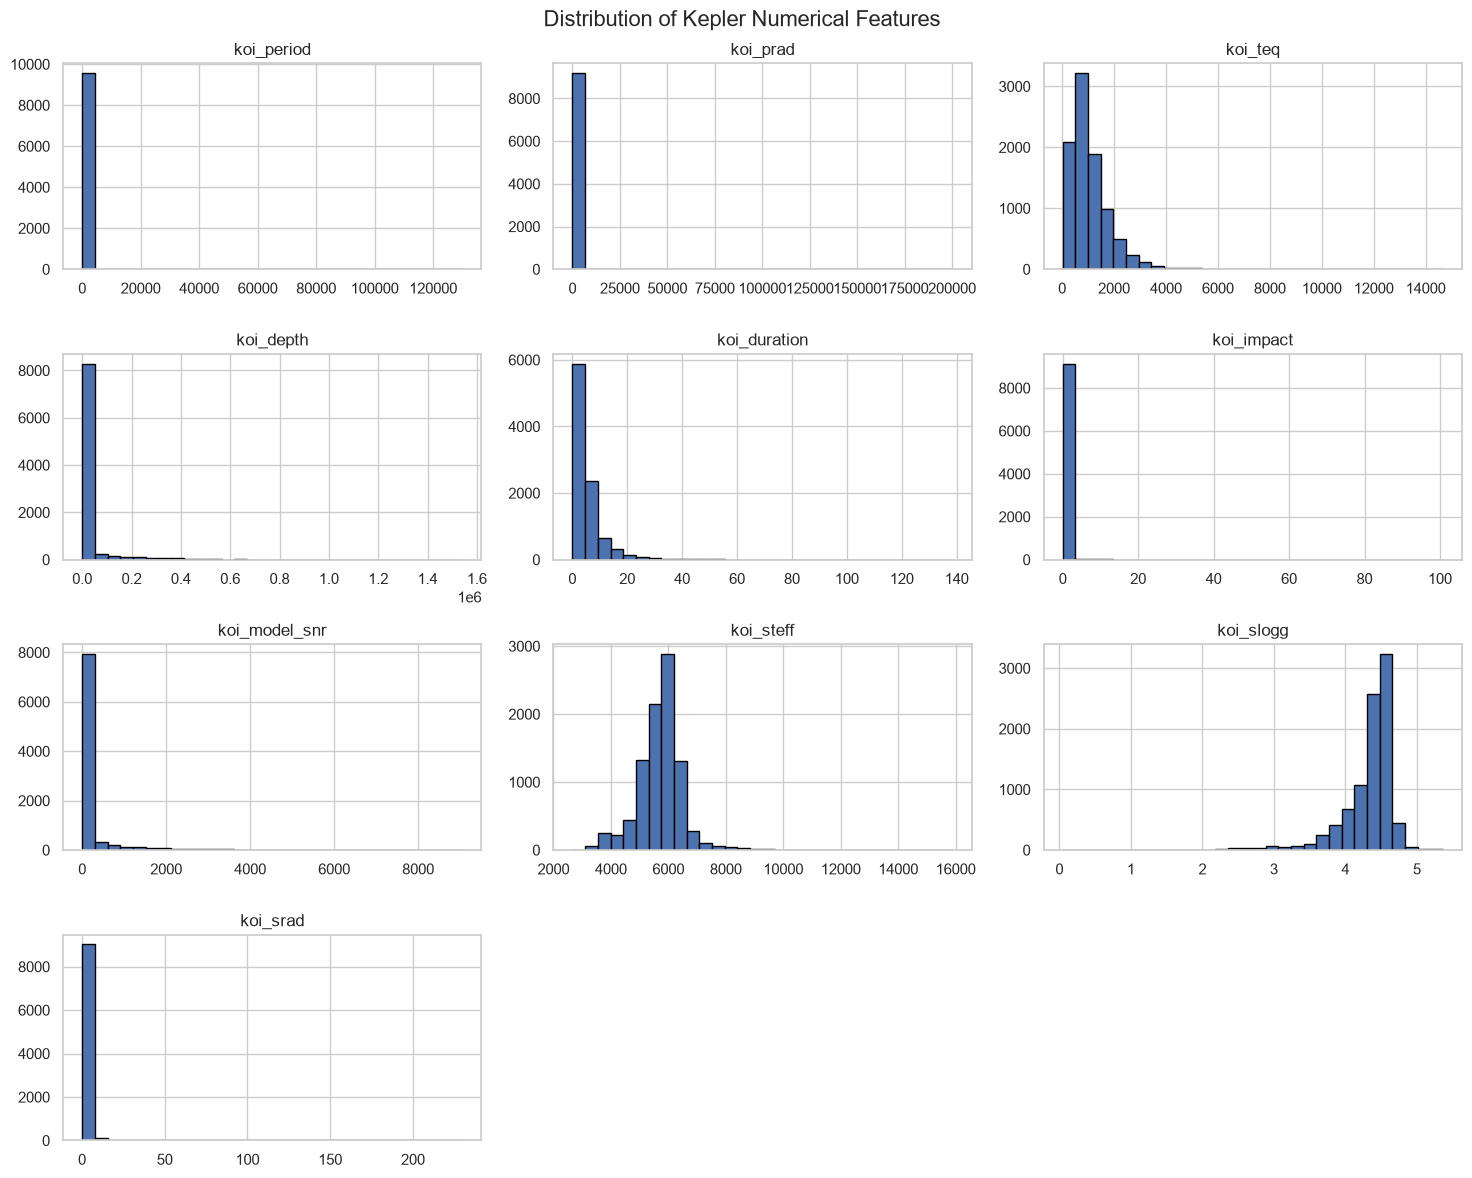

In [28]:
import matplotlib.pyplot as plt

kepler_features = [
    'koi_period',
    'koi_prad',
    'koi_teq',
    'koi_depth',
    'koi_duration',
    'koi_impact',
    'koi_model_snr',
    'koi_steff',
    'koi_slogg',
    'koi_srad'
]

kepler[kepler_features].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Kepler Numerical Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [29]:
kepler[kepler_features].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
koi_period,9564.0,75.671358,1334.744046,0.241843,0.527676,0.705509,2.733684,9.752831,40.715178,371.5625,550.997903,890.505559,1.299958e+05
koi_prad,9201.0,102.891778,3077.639126,0.080000,0.520000,0.760000,1.400000,2.390000,14.930000,87.2100,369.200000,13055.560000,2.003460e+05
koi_teq,9201.0,1085.385828,856.351161,25.000000,196.000000,256.000000,539.000000,878.000000,1379.000000,2545.0000,4106.000000,8304.400000,1.466700e+04
koi_depth,9201.0,23791.335898,82242.683149,0.000000,24.100000,47.600000,159.900000,421.100000,1473.400000,172400.0000,416740.000000,718704.000000,1.541400e+06
koi_duration,9564.0,5.621606,6.471554,0.052000,0.798706,1.252135,2.437750,3.792600,6.276500,16.0270,30.047542,78.819374,1.385400e+02
koi_impact,9201.0,0.735105,3.348832,0.000000,0.003000,0.017000,0.197000,0.537000,0.889000,1.2510,1.782600,71.102340,1.008060e+02
koi_model_snr,9201.0,259.895001,795.806615,0.000000,5.000000,7.000000,12.000000,23.000000,78.000000,1550.9000,4355.500000,7871.660000,9.054700e+03
koi_steff,9201.0,5706.823280,796.857947,2661.000000,3638.000000,4330.000000,5310.000000,5767.000000,6112.000000,6726.0000,8144.000000,10878.400000,1.589600e+04
koi_slogg,9201.0,4.310157,0.432606,0.047000,2.520000,3.595000,4.218000,4.438000,4.543000,4.6690,4.813000,5.215000,5.364000e+00
koi_srad,9201.0,1.728712,6.127185,0.109000,0.443000,0.602000,0.829000,1.000000,1.345000,3.2980,13.056000,98.186000,2.299080e+02


In [30]:
outlier_results = []

for col in kepler_features:

    Q1 = kepler[col].quantile(0.25)
    Q3 = kepler[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = kepler[
        (kepler[col] < lower_bound) |
        (kepler[col] > upper_bound)
    ]

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
            len(outliers) / kepler[col].notna().sum()
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,koi_period,-54.238556,97.687418,1567,16.384358
1,koi_prad,-18.895000,35.225000,1469,15.965656
2,koi_teq,-721.000000,2639.000000,411,4.466906
3,koi_depth,-1810.350000,3443.650000,1798,19.541354
4,koi_duration,-3.320375,12.034625,869,9.086156
5,koi_impact,-0.841000,1.927000,82,0.891207
6,koi_model_snr,-87.000000,177.000000,1600,17.389414
7,koi_steff,4107.000000,7315.000000,552,5.999348
8,koi_slogg,3.730500,5.030500,663,7.205739
9,koi_srad,0.055000,2.119000,985,10.705358


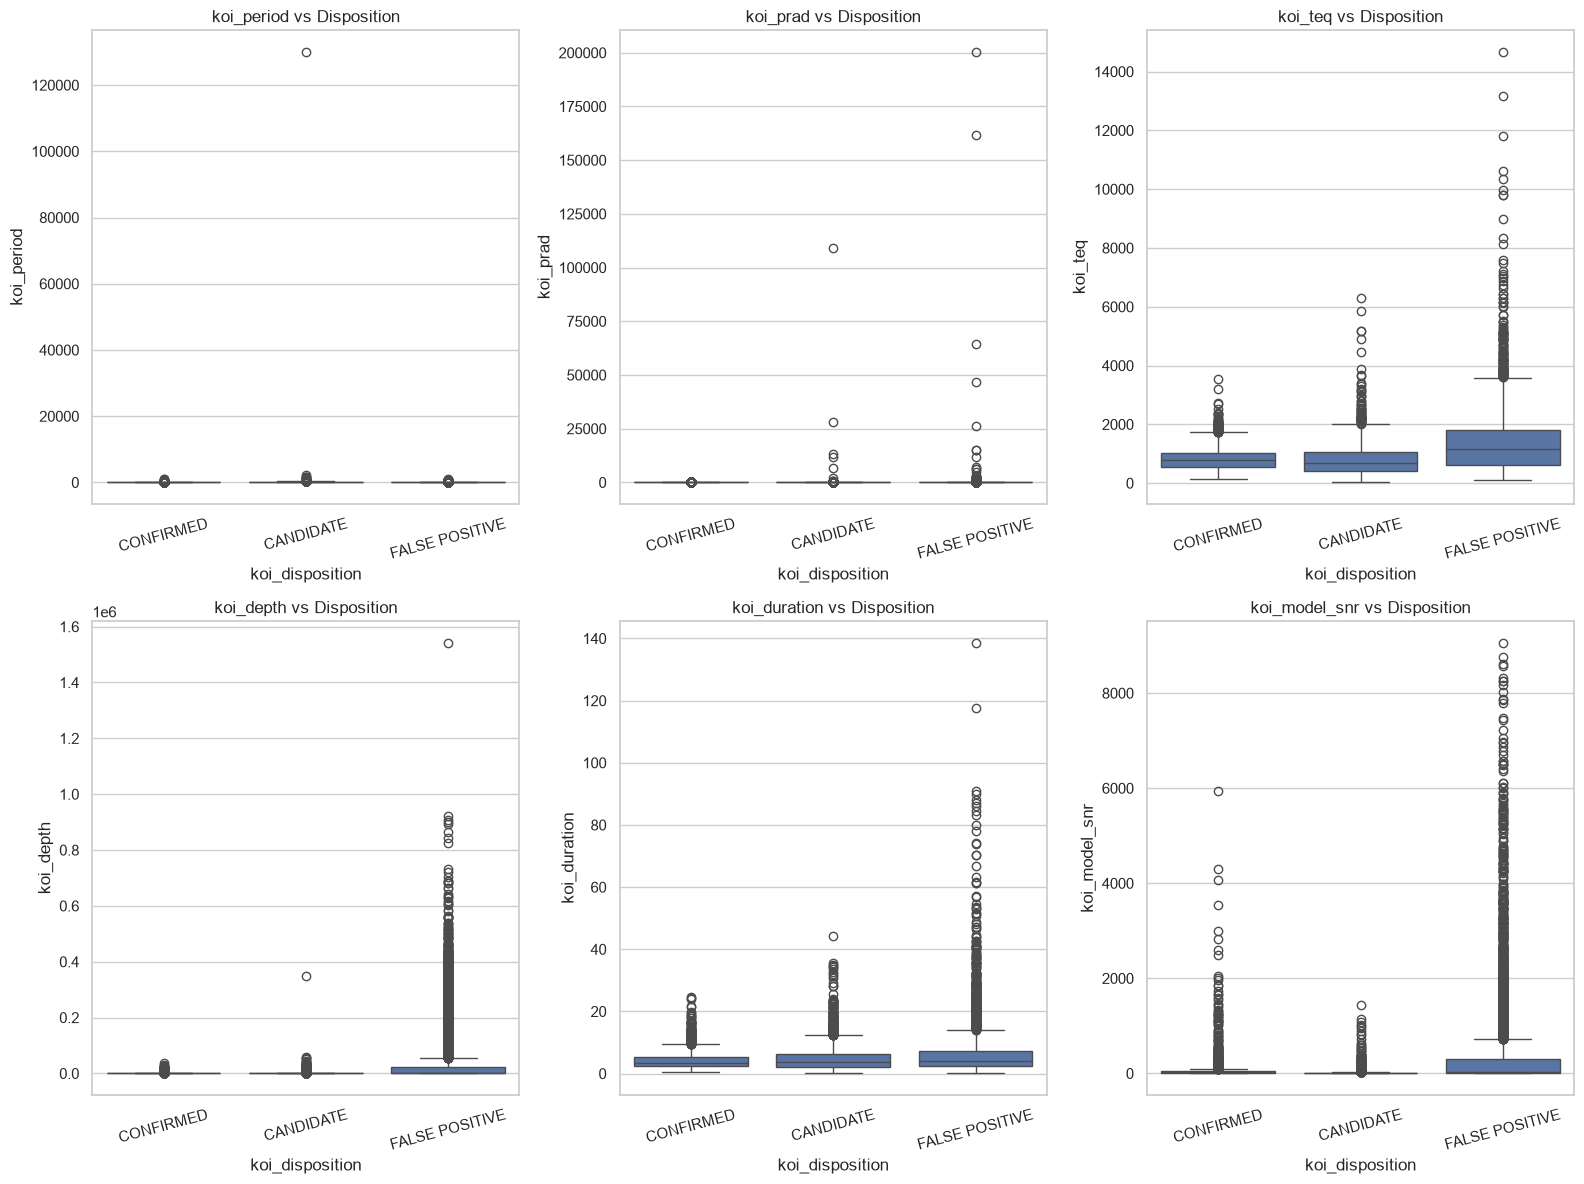

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

features_to_compare = [
    'koi_period',
    'koi_prad',
    'koi_teq',
    'koi_depth',
    'koi_duration',
    'koi_model_snr'
]

plt.figure(figsize=(16, 12))

for i, col in enumerate(features_to_compare, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=kepler,
        x='koi_disposition',
        y=col
    )

    plt.title(f'{col} vs Disposition')
    plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [32]:
features_to_compare = [
    'koi_period',
    'koi_prad',
    'koi_teq',
    'koi_depth',
    'koi_duration',
    'koi_model_snr'
]

class_summary = kepler.groupby('koi_disposition')[
    features_to_compare
].agg(['median', 'mean', 'std'])

class_summary.T

koi_disposition         CANDIDATE    CONFIRMED  FALSE POSITIVE
koi_period    median    20.019596    11.355619        5.243853
              mean     167.836690    27.911368       65.138933
              std     2926.291939    56.520052      131.497315
koi_prad      median     1.740000     2.160000        8.970000
              mean      97.994720     2.861945      164.841606
              std     2639.809162     3.404032     4020.542997
koi_teq       median   691.000000   777.000000     1152.500000
              mean     815.651895   831.806628     1347.616325
              std      581.779221   378.180998     1054.358946
koi_depth     median   241.700000   448.800000      575.950000
              mean    1371.046343  1051.850801    46583.965408
              std     9199.936499  2490.572303   111850.005504
koi_duration  median     3.604500     3.492000        4.057000
              mean       5.271018     4.246667        6.545650
              std        4.866989     2.741207        8.177067
koi_model_snr median    11.000000    28.600000       34.250000
              mean      30.283235    78.740168      462.320581
              std       91.933342   261.151535     1070.204147

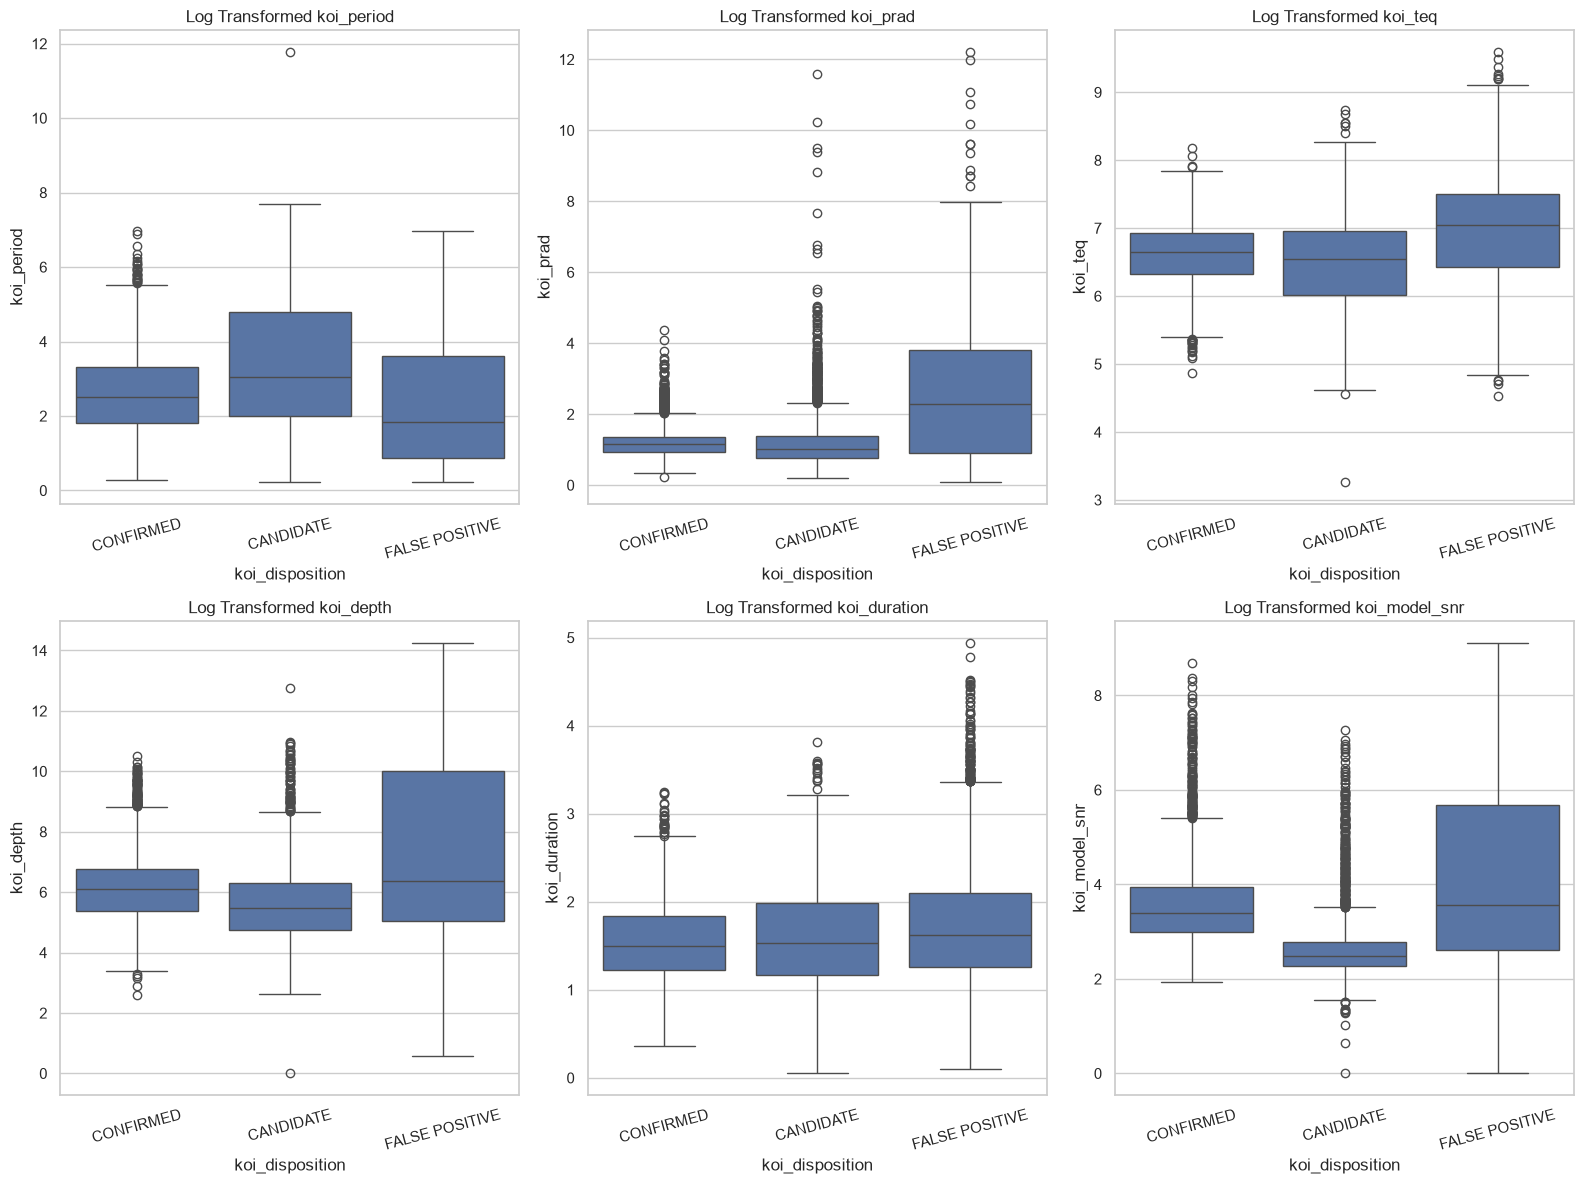

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

features_to_compare = [
    'koi_period',
    'koi_prad',
    'koi_teq',
    'koi_depth',
    'koi_duration',
    'koi_model_snr'
]

log_kepler = kepler[
    ['koi_disposition'] + features_to_compare
].copy()

for col in features_to_compare:
    log_kepler[col] = np.log1p(log_kepler[col])

plt.figure(figsize=(16, 12))

for i, col in enumerate(features_to_compare, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=log_kepler,
        x='koi_disposition',
        y=col
    )

    plt.title(f'Log Transformed {col}')
    plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

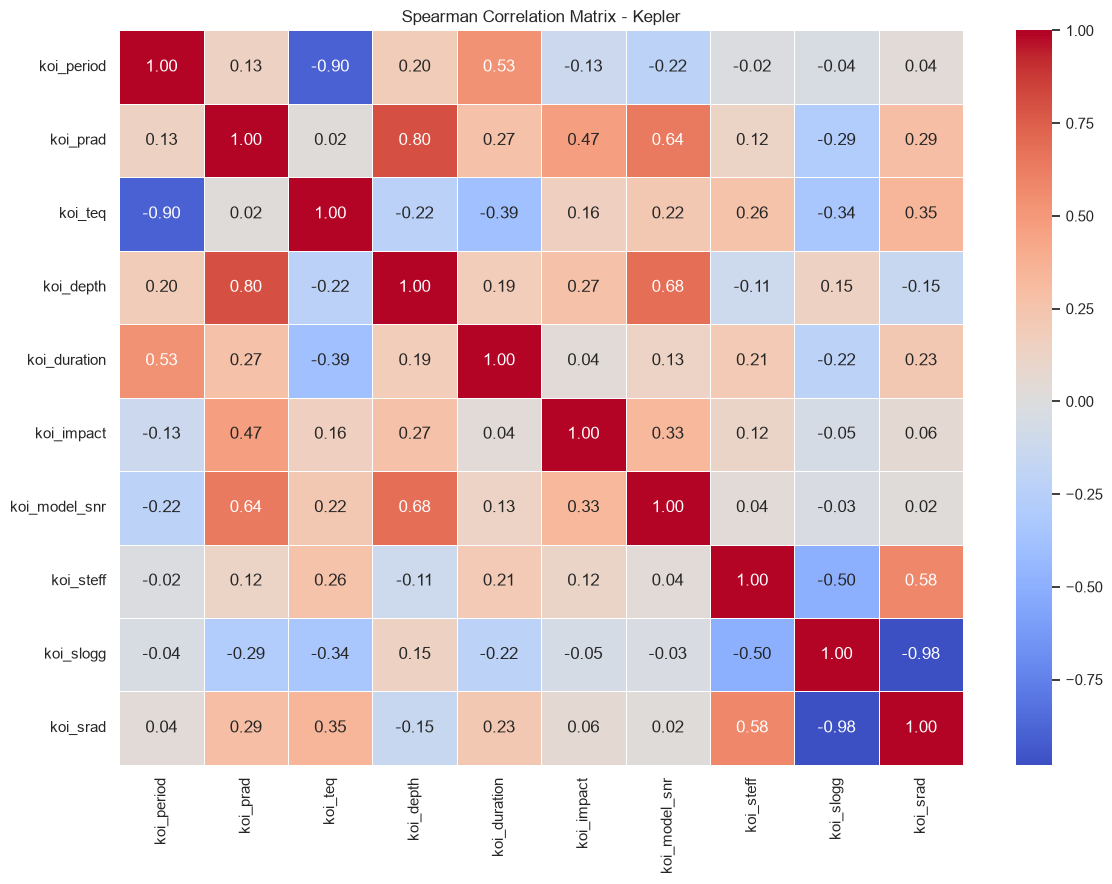

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_features = [
    'koi_period',
    'koi_prad',
    'koi_teq',
    'koi_depth',
    'koi_duration',
    'koi_impact',
    'koi_model_snr',
    'koi_steff',
    'koi_slogg',
    'koi_srad'
]

correlation_matrix = kepler[
    correlation_features
].corr(method='spearman')

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Spearman Correlation Matrix - Kepler')
plt.tight_layout()
plt.show()

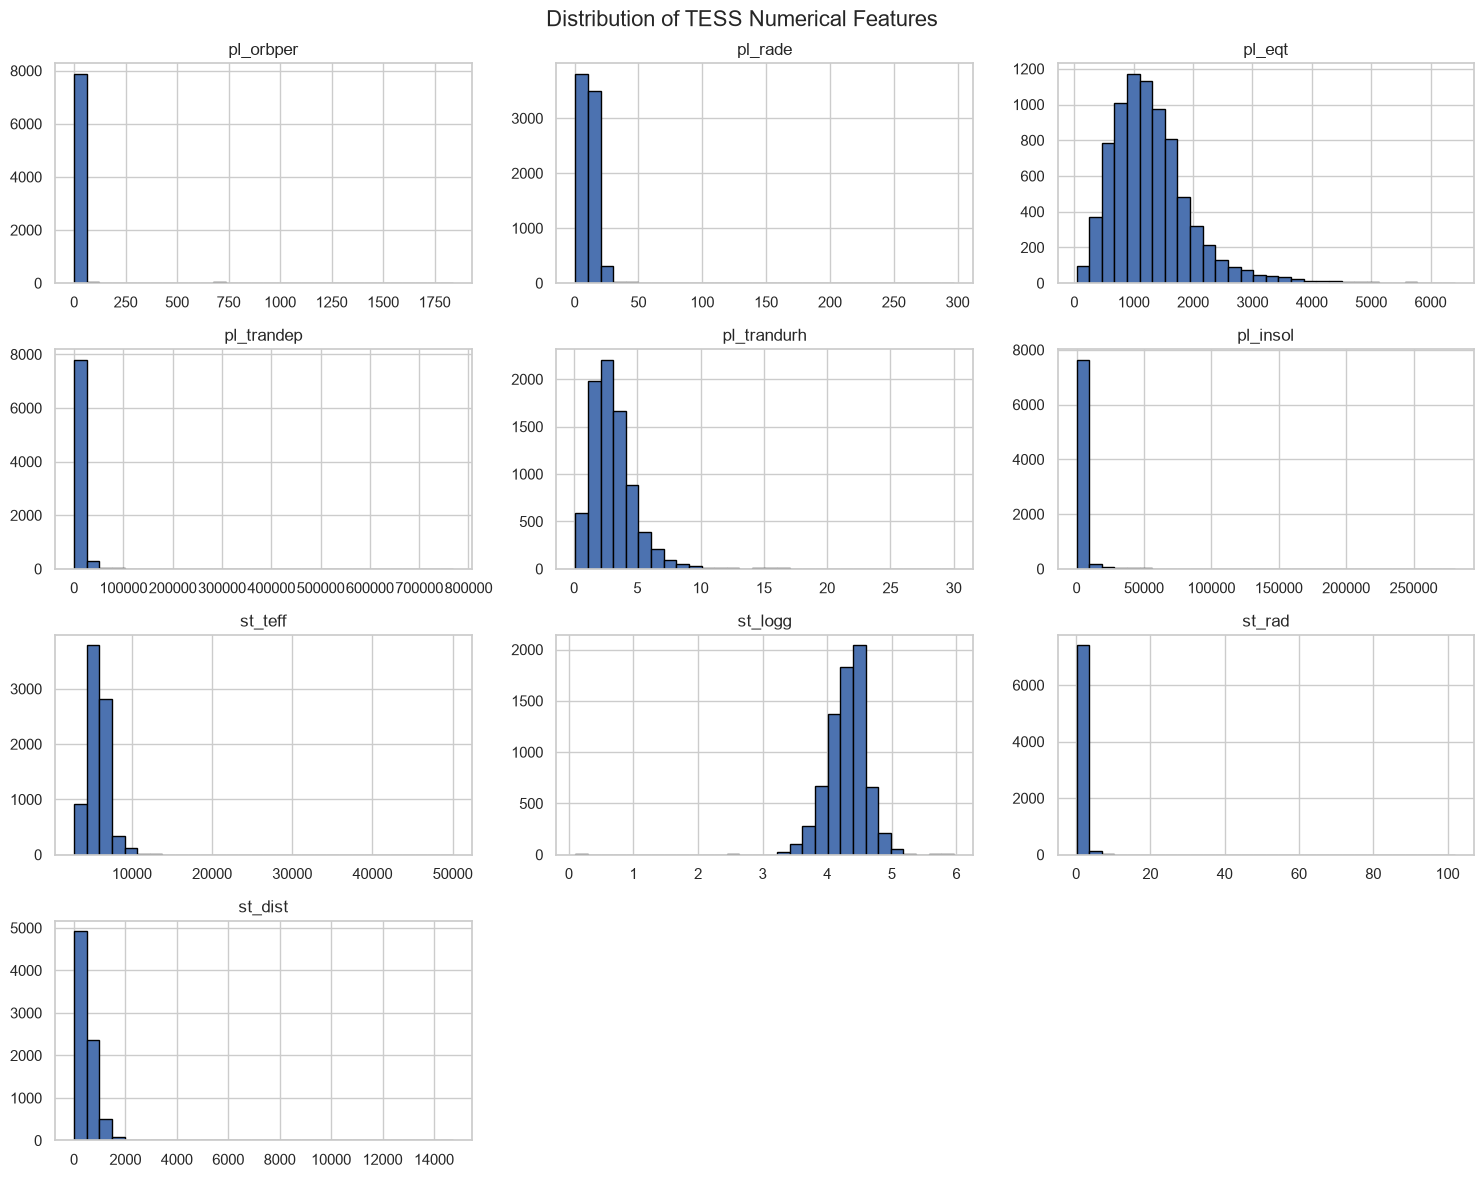

In [35]:
import matplotlib.pyplot as plt

tess_features = [
    'pl_orbper',
    'pl_rade',
    'pl_eqt',
    'pl_trandep',
    'pl_trandurh',
    'pl_insol',
    'st_teff',
    'st_logg',
    'st_rad',
    'st_dist'
]

tess[tess_features].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of TESS Numerical Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [36]:
tess[tess_features].describe(
    percentiles=[
        0.01, 0.05, 0.25, 0.50,
        0.75, 0.95, 0.99, 0.999
    ]
).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
pl_orbper,8066.0,17.723236,97.344199,0.152076,0.439602,0.866913,2.519329,4.152482,8.204959,27.210484,701.489696,1438.654187,1837.889731
pl_rade,7656.0,10.291567,8.411719,0.552507,1.129008,1.805631,4.547985,10.486100,13.941000,20.084600,27.548179,53.933966,297.111726
pl_eqt,7863.0,1298.941519,698.796525,37.000000,229.175099,432.033598,824.000000,1193.000000,1607.177074,2553.800000,3741.320000,5584.702747,6413.000000
pl_trandep,8175.0,8216.099937,16986.948387,24.583493,176.245610,380.000000,1450.912515,4735.000000,10294.500000,24453.850764,50475.078000,180843.992800,767910.313098
pl_trandurh,8171.0,3.089388,1.893665,0.101000,0.512304,0.993375,1.848845,2.756000,3.851470,6.236136,9.529948,17.306739,30.015619
pl_insol,7990.0,2352.489573,11040.346238,0.000342,0.643878,7.027188,88.100203,378.485000,1225.866593,7785.846371,38394.394107,167489.445198,280833.000000
st_teff,8000.0,5788.016249,1462.777081,2808.000000,3230.000000,3625.000000,5215.000000,5799.350000,6294.000000,7810.050000,9600.030000,13253.643000,50000.000000
st_logg,7273.0,4.304721,0.303534,0.100000,3.540000,3.790000,4.120000,4.330000,4.500000,4.750000,4.981455,5.564720,5.960650
st_rad,7544.0,1.400522,1.566177,0.114827,0.275157,0.513161,0.890000,1.236045,1.660000,2.620000,4.345700,8.819680,102.030000
st_dist,7952.0,481.052457,548.605855,6.531270,23.689352,55.104415,181.680750,370.553000,652.761000,1134.602500,1792.696100,7303.016360,14728.300000


In [37]:
tess_outlier_results = []

for col in tess_features:

    Q1 = tess[col].quantile(0.25)
    Q3 = tess[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = tess[
        (tess[col] < lower_bound) |
        (tess[col] > upper_bound)
    ]

    outlier_count = len(outliers)

    outlier_percentage = (
        outlier_count / tess[col].notna().sum()
    ) * 100

    tess_outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier Percentage': outlier_percentage
    })

tess_outlier_df = pd.DataFrame(tess_outlier_results)

tess_outlier_df

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,pl_orbper,-6.009114,16.733403,819,10.153732
1,pl_rade,-9.541538,28.030523,72,0.940439
2,pl_eqt,-350.765611,2781.942685,293,3.726313
3,pl_trandep,-11814.468712,23559.881227,443,5.418960
4,pl_trandurh,-1.155093,6.855408,277,3.390038
5,pl_insol,-1618.549382,2932.516179,958,11.989987
6,st_teff,3596.500000,7912.500000,736,9.200000
7,st_logg,3.550000,5.070000,123,1.691187
8,st_rad,-0.265000,2.815000,282,3.738070
9,st_dist,-524.939625,1359.381375,197,2.477364


In [38]:
print(tess['tfopwg_disp'].value_counts())

print("\nClass percentages:")
print(
    tess['tfopwg_disp'].value_counts(normalize=True) * 100
)

tfopwg_disp
PC     4832
FP     1319
CP      821
KP      609
APC     494
FA       98
Name: count, dtype: int64

Class percentages:
tfopwg_disp
PC     59.121498
FP     16.138505
CP     10.045271
KP      7.451364
APC     6.044292
FA      1.199070
Name: proportion, dtype: float64


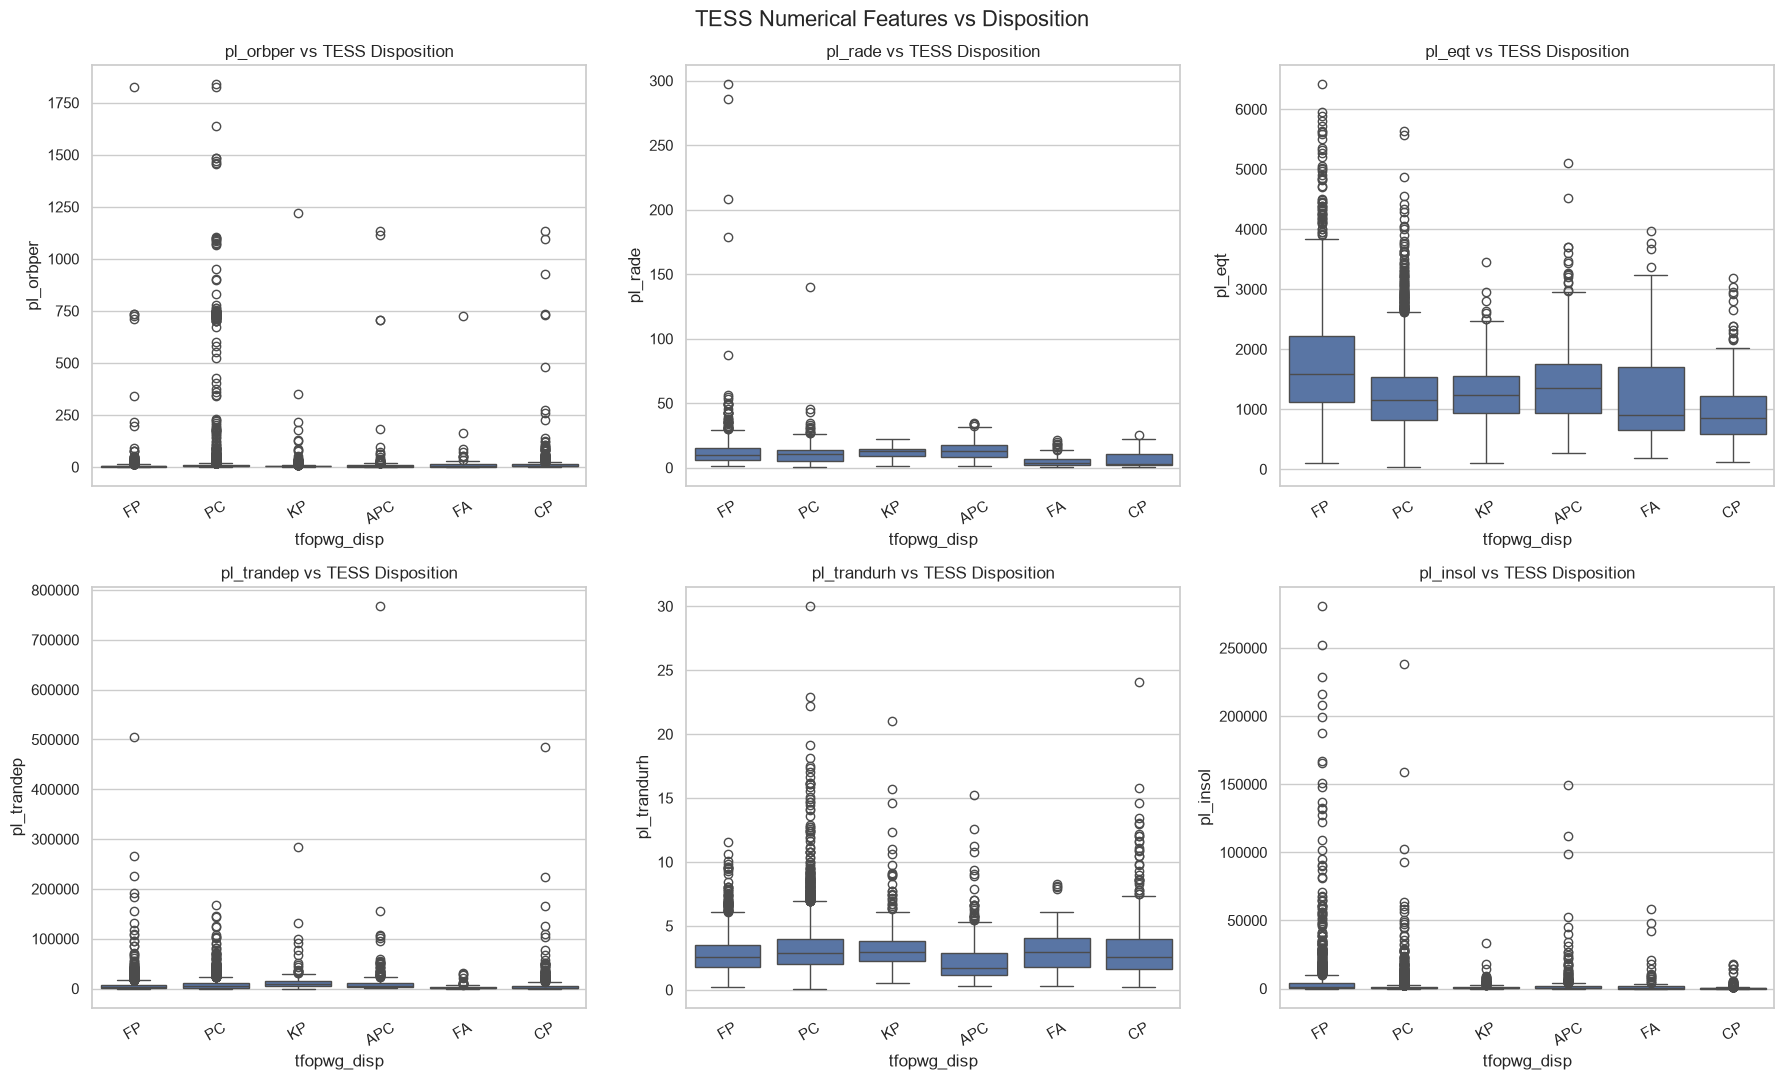

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

tess_class_features = [
    'pl_orbper',
    'pl_rade',
    'pl_eqt',
    'pl_trandep',
    'pl_trandurh',
    'pl_insol'
]

tess_plot_data = tess.dropna(subset=['tfopwg_disp']).copy()

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, col in zip(axes.flatten(), tess_class_features):

    sns.boxplot(
        data=tess_plot_data,
        x='tfopwg_disp',
        y=col,
        ax=ax
    )

    ax.set_title(f'{col} vs TESS Disposition')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle(
    'TESS Numerical Features vs Disposition',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [40]:
tess_class_summary = tess_plot_data.groupby(
    'tfopwg_disp'
)[tess_class_features].median()

tess_class_summary

,pl_orbper,pl_rade,pl_eqt,pl_trandep,pl_trandurh,pl_insol
tfopwg_disp,,,,,,
APC,3.317173,12.834242,1360.583469,5360.839818,1.699000,639.764500
CP,5.643085,3.218830,845.724226,1762.000000,2.584000,96.470700
FA,6.210344,3.426200,901.000000,1157.610103,2.982841,148.490368
FP,2.828914,9.973332,1582.000000,2940.000000,2.597000,1122.820000
KP,3.611262,12.908315,1233.532835,10014.258740,2.946246,513.604359
PC,4.464476,10.803700,1157.000000,5334.483379,2.900196,320.888500


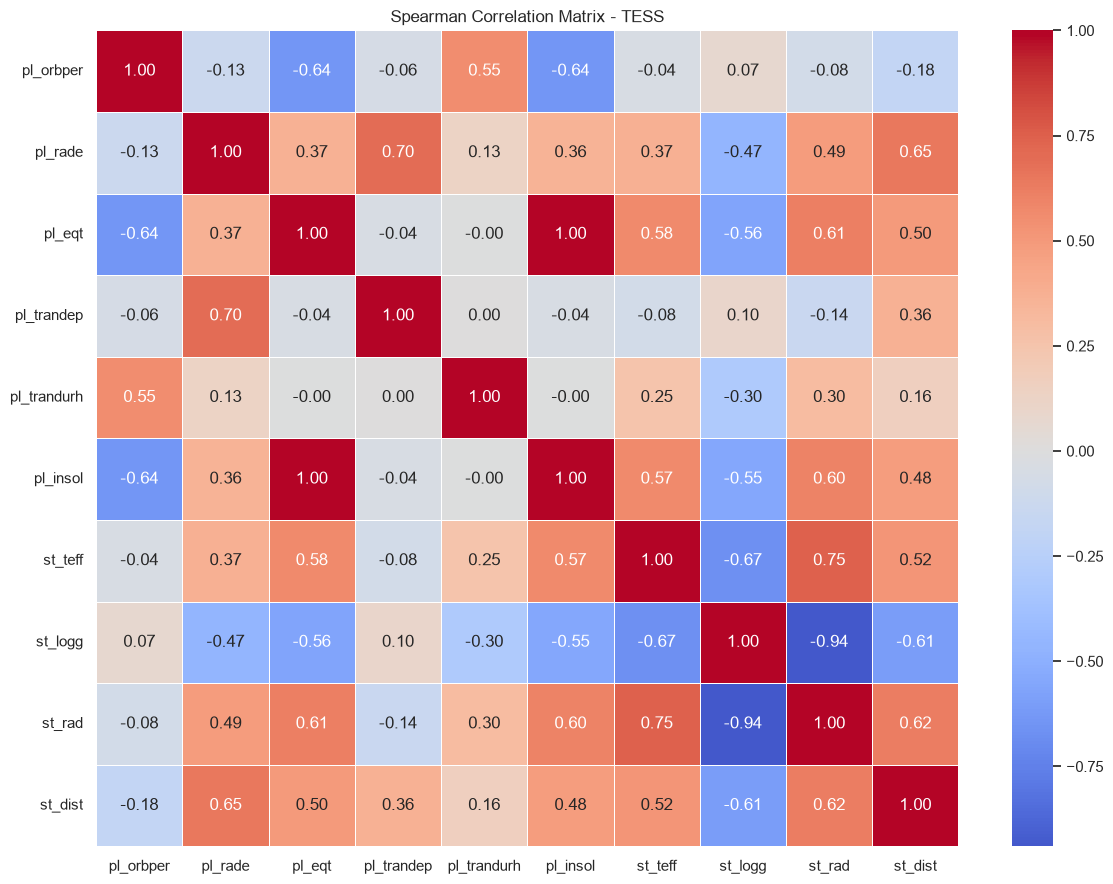

In [41]:
tess_correlation_matrix = tess[
    tess_features
].corr(method='spearman')

plt.figure(figsize=(12, 9))

sns.heatmap(
    tess_correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Spearman Correlation Matrix - TESS')

plt.tight_layout()
plt.show()


In [42]:

print("Kepler missing target values:",
      kepler['koi_disposition'].isnull().sum())

print("TESS missing target values:",
      tess['tfopwg_disp'].isnull().sum())

Kepler missing target values: 0
TESS missing target values: 2


In [43]:
import os

# Create processed data directory
os.makedirs("../data/processed", exist_ok=True)

# Export cleaned datasets
kepler_clean.to_csv(
    "../data/processed/kepler_clean.csv",
    index=False
)

tess_clean.to_csv(
    "../data/processed/tess_clean.csv",
    index=False
)

print("Cleaned datasets exported successfully!")

Cleaned datasets exported successfully!
